<a href="https://colab.research.google.com/github/chrisnelsonlab/BMEG4623/blob/master/5_Transport_FDM_DRAFT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<img src=https://brand.uark.edu/_resources/images/UA_Logo_Horizontal.jpg width="400" height="96">

####BMEG 4623 - Tranposrt phenomenon in biomedical engineering
####For more information, check out the Nelson lab for Therapeutic Genome Engineering (https://nelsonlab.uark.edu/)

For image credits, see the linked URL

#1. Introduction

The goal for today is to derive the Finite Difference Method for Heat Transfer

For any object, we can discretize the object into a grid. Here we are showing two dimmensions:

<img src = https://raw.githubusercontent.com/chrisnelsonlab/BMEG4623/refs/heads/master/Images/FDM.png>


In class we derived the following equation:

$$
0 = -4T_{m,n} + T_{m,n-1} + T_{m,n+1}+ + T_{m-1,n} + T_{m+1,n} + \frac{\dot{Q}}{k} \, \Delta x \, \Delta y
$$


Let's try an example:

<img src =https://raw.githubusercontent.com/chrisnelsonlab/BMEG4623/refs/heads/master/Images/FDM_e1.png>

Let's solve for coefficients:


$$
\begin{bmatrix}
c_1 \\ c_2 \\ c_3 \\ c_4
\end{bmatrix}
=
\begin{bmatrix}
-4 & 1 & 1 & 0 \\
1 & -4 & 0 & 1 \\
1 & 0 & -4 & 1 \\
0 & 1 & 1 & -4
\end{bmatrix}
\begin{bmatrix}
T_{1} \\ T_{2} \\ T_{3} \\ T_{4}
\end{bmatrix}
$$




In [ ]:
import numpy as np

# Define a 4x4 matrix
A = np.array([
    [-4, 1, 1, 0],
    [1, -4, 0, 1],
    [1, 0, -4, 1],
    [0, 1, 1, -4]
])

# Create a 4x1 matrix
C = np.array([
    [-150],
    [-300],
    [-350],
    [-500]
])

# Invert the matrix
A_inv = np.linalg.inv(A)

Tm = A_inv@C
# or use np.matmul(A_inv, b)
#important note, don't use A_inv*C


print(Tm)

# Print results
print("Original matrix A:")
print(A)

print("\nInverse of A:")
print(A_inv)

# Verify the inversion (A * A_inv ≈ I)
print("\nCheck (A @ A_inv):")
print(np.round(A @ A_inv, 3))  # Rounded for clarity

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Setup ---
n = 100  # grid size
TempArray = np.zeros((n, n))

# Boundary conditions (°C)
TempArray[0, :] = 21
TempArray[-1, :] = 21
TempArray[:, 0] = 21
TempArray[:, -1] = 21

# Parameters
heatgen = 8000   # W/m^3
k = 0.6          # W/m·K
dx = 0.02        # m
dy = dx
maxerror = 0.01 * n * n

# --- Gauss–Seidel iteration ---
for loop in range(200):
    Error = 0
    for i in range(1, n-1):
        for j in range(1, n-1):
            TempValue = TempArray[i, j]
            TempArray[i, j] = (
                (heatgen * dx * dy / (4 * k))
                + TempArray[i-1, j]
                + TempArray[i+1, j]
                + TempArray[i, j-1]
                + TempArray[i, j+1]
            ) / 4
            Error += abs(TempValue - TempArray[i, j])

    # --- Visualization ---
    plt.clf()
    ax = plt.axes(projection='3d')
    X, Y = np.meshgrid(np.arange(n), np.arange(n))
    ax.plot_surface(X, Y, TempArray, cmap='inferno')
    ax.set_title(f"Iteration: {loop+1}")
    plt.pause(0.1)

    # --- Convergence check ---
    if Error < maxerror:
        print(f"Converged after {loop+1} iterations, Error={Error:.4f}")
        break

plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# --- Grid and parameters ---
n = 50  # smaller grid for speed in Colab
TempArray = np.zeros((n, n))
TempArray[0, :] = 21
TempArray[-1, :] = 21
TempArray[:, 0] = 21
TempArray[:, -1] = 21

heatgen = 1000
k = 0.6
dx = dy = 0.02
maxerror = 0.01 * n * n
max_loops = 200

X, Y = np.meshgrid(np.arange(n), np.arange(n))
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# --- Animation function ---
n_skip = 5  # update every 5 iterations
loop_count = 0  # keep track of total iterations

def update(frame):
    global TempArray, loop_count
    Error = 0
    for _ in range(n_skip):
        loop_count += 1
        for i in range(1, n-1):
            for j in range(1, n-1):
                TempValue = TempArray[i, j]
                TempArray[i, j] = (
                    heatgen*dx*dy/(4*k) +
                    TempArray[i-1, j] + TempArray[i+1, j] +
                    TempArray[i, j-1] + TempArray[i, j+1]
                ) / 4
                Error += abs(TempValue - TempArray[i, j])
        if Error < maxerror:
            anim.event_source.stop()
            print(f"Converged after {loop_count} iterations")
            anim.event_source.stop()

    ax.clear()
    ax.plot_surface(X, Y, TempArray, cmap=cm.inferno)
    ax.set_zlim(0, 100)
    ax.set_title(f"Iteration {loop_count}")


# --- Run animation ---
anim = FuncAnimation(fig, update, frames=max_loops, interval=100)

# --- Display in Colab ---
HTML(anim.to_jshtml())


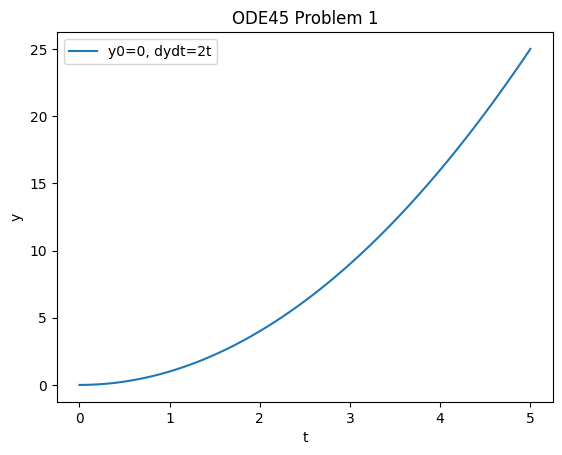

Press Enter to continue to the next problem...


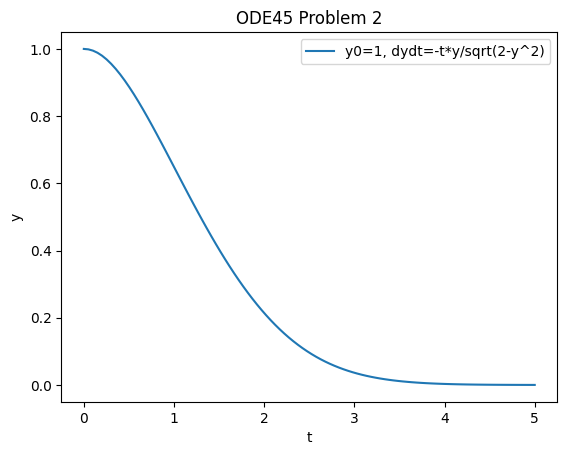

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- Problem 1 ---
def ode45func1(t, y):
    return 2*t

y0 = 0
tspan = (0, 5)

sol1 = solve_ivp(ode45func1, tspan, [y0], method='RK45', t_eval=np.linspace(tspan[0], tspan[1], 100))

plt.figure()
plt.plot(sol1.t, sol1.y[0], label='y0=0, dydt=2t')
plt.xlabel('t')
plt.ylabel('y')
plt.title('ODE45 Problem 1')
plt.legend()
plt.show()

input("Press Enter to continue to the next problem...")

# --- Problem 2 ---
def ode45func2(t, y):
    return -t*y/np.sqrt(2 - y**2)

y0 = 1
tspan = (0, 5)

sol2 = solve_ivp(ode45func2, tspan, [y0], method='RK45', t_eval=np.linspace(tspan[0], tspan[1], 100))

plt.figure()
plt.plot(sol2.t, sol2.y[0], label='y0=1, dydt=-t*y/sqrt(2-y^2)')
plt.xlabel('t')
plt.ylabel('y')
plt.title('ODE45 Problem 2')
plt.legend()
plt.show()


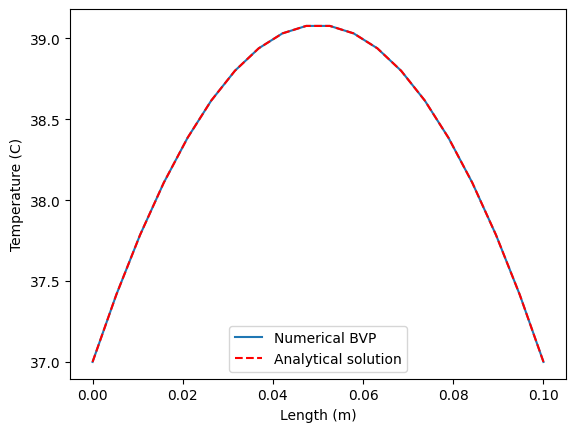

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_bvp

# --- Parameters ---
heatgen = 1000
k = 0.6
L = 0.1
Ts = 37

# --- Spatial grid ---
x = np.linspace(0, L, 20)

# --- Initial guess for [T, dT/dx] ---
# First row: T1, second row: T2 (dT/dx)
y_init = np.zeros((2, x.size))
y_init[0, :] = 37   # initial guess for T1
y_init[1, :] = 1    # initial guess for T2

# --- Define ODE system ---
def odefun(x, T, q, k):
    T1 = T[0, :]
    T2 = T[1, :]
    dT1dx = T2
    dT2dx = np.zeros_like(x) -q/k #+ T1   # d2T/dx2 = -q/k
    return np.vstack((dT1dx, dT2dx))

# --- Define boundary conditions ---
def bcfun(T0, TL):
    #TYPE I BC
    #res = [T_0(1)-100;
    #       T_L(1)-0];
    res0 = T0[0] - Ts   # T(0) - Ts = 0
    resL = TL[0] - Ts   # T(L) - Ts = 0
    return np.array([res0, resL])


    #Another example Type II BC (Symmetry) and type I on the other side
    # Type II: Symmetry at x=0; specified temperature at x=L
    #UNCOMMENTres0 = T0[1]       # T'(0) = 0
    #UNCOMMENTresL = TL[0] - Ts  # T(L) - Ts = 0

    #UNCOMMENTreturn np.array([res0, resL])


def bcfun(T0, TL):
    # Type III: Convection at both boundaries
    #UNCOMMENTh = 10
    #UNCOMMENTT_inf = 21

    #UNCOMMENTres0 = k * T0[1] - h * (T0[0] - T_inf)
    #UNCOMMENTresL = -k * TL[1] - h * (TL[0] - T_inf)

    #UNCOMMENTreturn np.array([res0, resL])

# --- Solve BVP ---
sol = solve_bvp(lambda x, T: odefun(x, T, heatgen, k),
                bcfun,
                x, y_init)

# --- Extract solution ---
x_sol = sol.x
T1_sol = sol.y[0, :]
T2_sol = sol.y[1, :]

# --- Plot numerical solution ---
plt.figure()
plt.plot(x_sol, T1_sol, label='Numerical BVP')

# --- Analytical solution (for demonstration) ---
T_an = -heatgen*x_sol**2/(2*k) + heatgen*L/2/k*x_sol + Ts
plt.plot(x_sol, T_an, 'r--', label='Analytical solution')
plt.xlabel('Length (m)')
plt.ylabel('Temperature (C)')
plt.legend()
plt.show()